First we test that all the packages are installed correctly

In [1]:
!pip install iisignature
!pip install esig

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 11.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for iisignature: filename=iisignature-0.24-cp312-cp312-linux_x86_64.whl size=3246774 sha256=467ddc639c865c15b04abf89a82474a793c6c7d991081abff7c56bbcb3b72231
  Stored in directory: /root/.cache/pip/wheels/7d/b3/8c/168fb7d3b31255a501dea7fa1f5e5098e63ec61a786eeb0156
Successfully built iisignature
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 92.1 MB/s eta 0:00:00


In [3]:
import helper_sigs
import numpy as np
import matplotlib.pyplot as plt
import sympy
import iisignature
import esig


##Theory

$\mathbb{R}^d$ is the space of $d$-ples of real numbers, we can then define the tensor product
$$(\mathbb{R}^d)^{\otimes 2} = \mathbb{R}^d \otimes \mathbb{R}^d \simeq \mathbb{R}^{d^2}$$
to be the space of $2$-ples of elements of $\mathbb{R}^d$, every element of $(\mathbb{R}^d)^{\otimes 2}$ will thus be defined by $d^2$ scalars, we can then define inductively
$$(\mathbb{R}^d)^{\otimes n} := (\mathbb{R}^{d})^{\otimes (n-1)} \otimes (\mathbb{R}^d) \simeq \mathbb{R}^{d^n}$$
of which every element whill be defined by $d^n$ scalars, we then take the vector direct sum of all of these vector spaces and we thus obtain
$$T((\mathbb{R}^d)) := \bigoplus_{n=0}^{\infty} (\mathbb{R}^d)^{\otimes n}$$

$T(\mathbb{R}^d)$ is therefore defined as the space of sequences $(\bm{a}_n)_{n \geq 0}$ such that $\bm{a}_n \in (\mathbb{R}^d)^{\otimes n}$, we then define the new space

$$T(\mathbb{R}^d) := \{ (\bm{a}_n)_{n \geq 0} \in T((\mathbb{R}^d)) \: : \: \exists N, :, \bm{a}_n = 0 \forall n \geq N  \}$$

suppose $\mathbb{S} \in T((\mathbb{R}^d))$ and $\ell \in T(\mathbb{R}^d)$, we can define define the scalar product $\langle \ell , \mathbb{S} \rangle$ as

$$\langle \ell , \mathbb{S} \rangle := \sum_{n=0}^{\infty} \left( \langle \ell^{(n)} , \mathbb{S}^{(n)} \rangle_{(\mathbb{R}^{d})^{\otimes n}} \right)$$

where the inner product $\langle \ell^{(n)} , \mathbb{S}^{(n)} \rangle_{(\mathbb{R}^{d})^{\otimes n}}$ is defined as the component-wise product, in practice it will be something of this sort
$$\langle \ell^{(n)} , \mathbb{S}^{(n)} \rangle_{(\mathbb{R}^{d})^{\otimes n}} = \sum_{v \in V^{(n)}_d}\ell^{(n)}_{v} \mathbb{S}^{(n)}_{v} $$
where $V^{(n)}_d$ denotes the set of all the $d^n$ components of $(\mathbb{R}^d)^{\otimes n}$


Suppose $X$ is a $C^1$ function from $[0,T]$ to $\mathbb{R}^d$, we can then define the $n$-th level signature of $X$, denoted $\text{Sig}^{(n)}(X)$, as a function from $[0,T]$ to $\mathbb{R}^{d^n} \sim (\mathbb{R}^d)^{\otimes n}$ in the following inductive way:

- $\text{Sig}^{(0)}(X)_{0,t} := 1$
- $\text{Sig}^{(1)}(X)_{0,t}$ is defined as the $\mathbb{R}^d$ vector $X_{t} - X_0$
- Assume $\text{Sig}^{(n)}(X)_{0,s}$ is defined as an element of $(\mathbb{R}^d)^{\otimes n}$ for all $s$, then we define $$\text{Sig}^{(n+1)}(X)_{0,t} := \int_{0}^{t} \text{Sig}^{(n)}(X)_{0,s} \circ \otimes dX_{s}$$
This will be an element of $(\mathbb{R}^d)^{\otimes (n*1)}$

We then use $\text{Sig}(X)_{0,t}$ to denote the sequence of signatures $$\text{Sig}(X)_{0,t} := (1,\text{Sig}^{(1)}(X)_{0,t},\text{Sig}^{(2)}(X)_{0,t},\dots,\text{Sig}^{(n)}(X)_{0,t},\dots)$$
which is clearly an element of $T((\mathbb{R}^d))$

#Numerical Results

##Alvaro Cartilla case

###Problem Set-Up

Here we reference the paper

Optimal execution with rough path signatures∗
Jasdeep Kalsi1
, Terry Lyons1, 2, and Imanol Perez Arribas

We introduce the following variables

- $\theta$ the trading speed controlled by the agent
- $S$ the unaffected (mid)price process
- $S^\theta$ the (mid)price process affected by the permanent price impact alone
- $\widehat{S}^{\theta}$ the execution price process, which is the price at which the agent executes the order by walking through the LOB and it's affected by both permanent and temporary price impact
- $Q^{\theta}$ the agent inventory
- $X^{\theta}$ the agent cash process or wealth level


We also define some parameters
- $\lambda$ the temporary price impact parameter
- $\kappa$ the permanent price impact parameter
- $q_0$ the liquidation amount

Moreover the following relations hold

$$Q^\theta_t = q_0 - \int_0^t \theta_s ds$$

$$S_t = S_0 + \sigma W_t$$
$$S^\theta_t = S_t - \kappa (q_0 - Q_t)$$
$$\widehat{S}^{\theta} = S_t - \kappa(q_0 - Q_t) - \lambda \theta_t$$
We want to liquidate $q_0$ shares of the stock $S$ by time $T$, our revenue for the strategy will be the final wealth $X^{\theta}_T$ and what we will get by executing the remaining share at time $T$, we assume such term is $Q^{\theta}_T(S^{\theta}_T - \alpha Q^{\theta}_T)$, we also add a penalty for holding the inventory which is proportional to $\int_0^T (Q^\theta_t)^2 dt$, thus our value function for the strategy will be
$$V^\theta := X^\theta_T + Q^\theta_T (S^\theta_T - \alpha Q^\theta_T) - \phi \int_0^T (Q^\theta_t)^2 dt $$

Our goal is to find the $\theta$ which maximizes the expected value function

We can express each term in signature expansion with respect to the signatures of $S_t$, define $Sig(S)_t$ to be the signatures of the time augmented price process over the time-interval $[0,t]$, then we can consider the signature trading strategy

$$\theta = \langle \ell , Sig(S)_t \rangle$$
where $\ell$ is consant, with such a choice of $\theta$

We can moreover express

$$Q^\theta_t = \langle q_0 \emptyset - \ell 1, \text{Sig}(S_t) \rangle$$
$$S_t = S_0 + \int_0^t dS_u du = \langle S_0 \emptyset + 2 , \text{Sig}(S)_t \rangle$$

In [4]:
level = 4
truncate = 2*level + 1
dimension = 2
lamb = 0.01
k = 0.01
alpha =0.01
phi = 0.01
q0 = 1
sigma = 0.1
S0 = 0
T = 1

emptyword = helper_sigs.SigPoly(2,truncate,[1,0,0])
x = helper_sigs.SigPoly(2,truncate,[0,0,1])
t = helper_sigs.SigPoly(2,truncate,[0,1,0])

ell = helper_sigs.create_variable(dimension , level, truncate)
perm_impct = k*ell.tensor(t)
temp_impct = lamb*ell
g_l = ell.tensor(t)

print(alpha*emptyword + phi*t)

final_wealth = ((x + emptyword - perm_impct - temp_impct) * ell).tensor(t)

running_penalty = q0 * emptyword - ell.tensor(t)
running_penalty = (running_penalty*running_penalty).tensor(t)
running_penalty = phi*running_penalty

terminal_liquidation = q0*emptyword - ell.tensor(t)
terminal_liquidation = terminal_liquidation*((x + emptyword - perm_impct) - alpha*terminal_liquidation )


A = final_wealth - running_penalty + terminal_liquidation

print(A.level)
P = A.inner(    helper_sigs.exp_sigs_fawc( sigma = sigma, T = T, level = A.level )  )
print(P)
#print(second_term)

SigPoly(d=2, truncate_level=9, level=1 coeffs=[0.01, 0.01, 0.0])
9
-0.00333333333333333*x0**2 - 0.0025*x0*x1 - 1.16666666666667e-5*x0*x10 - 3.33333333333333e-6*x0*x13 - 3.76984126984127e-5*x0*x15 - 3.19444444444445e-6*x0*x18 - 1.11111111111111e-6*x0*x21 - 1.11111111111111e-6*x0*x27 - 0.000666666666666667*x0*x3 - 6.875e-8*x0*x30 - 3.75e-5*x0*x6 - 0.000138888888888889*x0*x7 + 1.0*x0*(1 - 0.01*x0) + 0.5*x0*(-0.01*x0 - 0.01*x1) + 0.166666666666667*x0*(-0.01*x1 - 0.01*x3) + 0.000208333333333333*x0*(-0.01*x10 - 0.01*x21) + 0.000208333333333333*x0*(-0.01*x13 - 0.01*x27) + 0.000833333333333333*x0*(-0.01*x13 - 0.01*x6) + 0.00833333333333333*x0*(-0.01*x15 - 0.01*x7) + 0.0416666666666667*x0*(-0.01*x3 - 0.01*x7) - 0.98*x0 - 0.0005*x1**2 - 7.63888888888889e-6*x1*x10 - 1.38888888888889e-6*x1*x13 - 2.23214285714286e-5*x1*x15 - 2.31150793650794e-6*x1*x18 - 6.4484126984127e-7*x1*x21 - 6.4484126984127e-7*x1*x27 - 0.000277777777777778*x1*x3 - 4.65277777777778e-8*x1*x30 - 2.16666666666667e-5*x1*x6 - 5.952

Theoretical optimal inventory

In [5]:
n = 252
time = np.linspace(0,T,n)

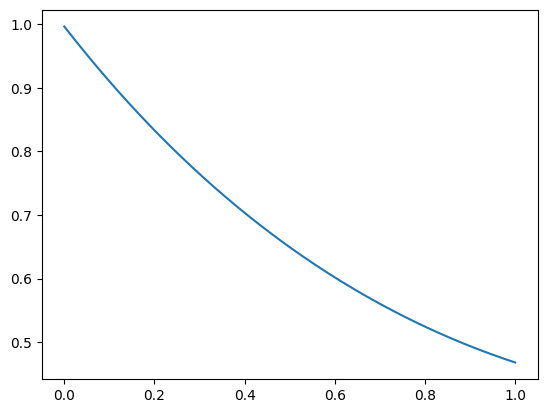

In [6]:
gamma = np.sqrt(phi / k)
zeta = ( alpha - 0.5*lamb + np.sqrt(k * phi) ) / ( alpha - 0.5 * lamb - np.sqrt(k * phi))
time_rev = np.flip(time)
chi = np.sqrt(k * phi)*(1 + zeta*np.exp(2*gamma*(time_rev)))/( 1 - zeta*np.exp(2*gamma*(time_rev)) )

dt = time[1] - time[0]

inventory = (dt / k) *np.cumsum(chi)
inventory = q0 * np.exp(inventory)

plt.plot(time,inventory)
plt.show()

Signature optimal inventory

Polynomial minimization

In [7]:
import sympy as sp
import numpy as np

# P: sympy expression already defined
# Example: P = ...

# 1) pick variables (x0..x6 present in P)
vars = sorted(P.free_symbols, key=lambda s: int(s.name[1:]))  # x0,x1,...
n = len(vars)
I = np.eye(n)

# 2) regularize: P_reg = P - rho * sum x_i^2
rho = 0  # start with 0, increase if needed
Preg = P - rho * sum(v**2 for v in vars)

# 3) compute Hessian and linear term (gradient at 0)
Hsym = sp.hessian(Preg, vars)
gsym = sp.Matrix([sp.diff(Preg, v) for v in vars])

H = np.array(Hsym, dtype=float)
g0 = np.array(gsym.subs({v: 0 for v in vars}), dtype=float).reshape(-1)

# 4) check concavity (need all eigenvalues < 0 for a unique max)
eig = np.linalg.eigvalsh(H)
print("eig min/max:", eig.min(), eig.max())

# If eig.max() >= 0, bump rho and rebuild Preg/H/g0, e.g.
# rho = 10.0

# 5) solve ∇Preg(x)=0  =>  H x + g0 = 0
x_star = -np.linalg.solve(H, g0)

# 6) objective value at optimum
f = sp.lambdify(vars, Preg, "numpy")
Pmax = float(f(*x_star))

print("rho =", rho)
print("x* =", x_star)
print("max Preg(x*) =", Pmax)

eig min/max: -0.046424059209324825 9.509293232608013e-07
rho = 0
x* = [ 0.90837192 -0.93329215  0.          0.55996368  0.          0.
 -0.29183144 -0.14516697  0.          0.          0.38362786  0.
  0.11116178  0.73114648  0.          0.18714121 -0.         -0.
  0.19221498  0.         -0.39182052 -0.21512365  0.          0.
  0.87338016 -0.66292611  0.         -0.60440766 -0.         -0.
  8.47444442]
max Preg(x*) = 0.9858632504482034


Signature optimal inventory visualized

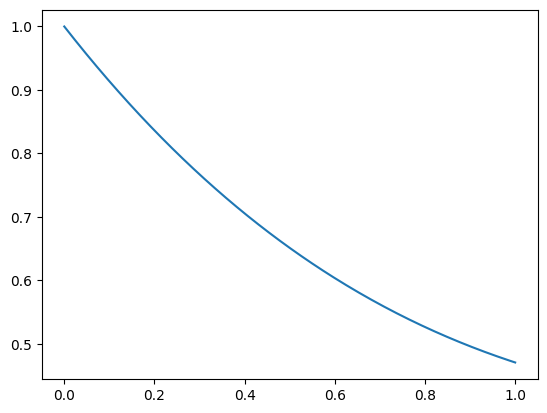

In [8]:
ell_star = helper_sigs.SigPoly(2, level, x_star.tolist())
inv_coeffs = np.array( (ell_star.tensor(t)).coefficients[1:] )

inventory_star = np.zeros(len(time))
for i in range(len(time)):
  cur_time = i * dt
  exp_sigs_cur_time = helper_sigs.exp_sigs_fawc( sigma = sigma, T = cur_time, level = level)
  exp_sigs_cur_time = np.array(exp_sigs_cur_time.coefficients[1:])
  inventory_star[i] = (q0 - np.dot( inv_coeffs, exp_sigs_cur_time ))


plt.plot(time,inventory_star)
plt.show()

Comparison

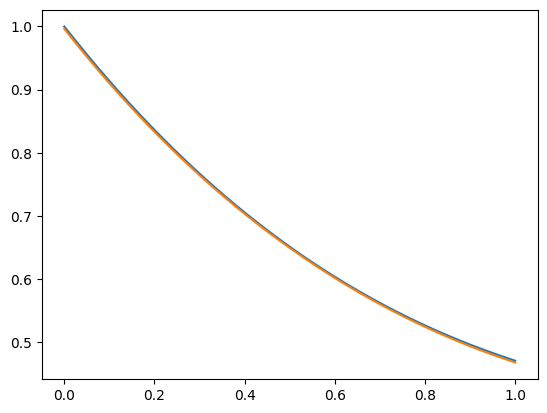

In [9]:
plt.plot(time,inventory_star)
plt.plot(time,inventory)
plt.show()

##GBM driver case

Here we reference the paper

ptimal Trade Execution under
Geometric Brownian Motion
in the Almgren and Chriss Framework
Jim Gatheral⇤, Alexander Schied‡

Problem set-up

In [ ]:
q0 = 1

ell = helper_sigs.create_variable(dimension , level, truncate)


### Base case

Here we run a very basic test, consider the control problem with objective functional
$$\mathbb{E}[V^\theta] = \mathbb{E}\left[\int_0^T \theta^2_t dt\right]$$
with the imposed condition $$\int_0^T \theta_t = I$$, we can impose this condition by considering the modified value function
$$\widetilde{V}^\theta := \int_0^T \theta^2_t dt + \lambda \left(I - \int_0^T \theta_t dt\right)^2$$ and setting a very high $\lambda$, another method consists in considering
$$\tilde{\theta}_t := \theta_t + \frac{1}{T}\int_0^t (I - \theta_s) ds$$
and then defining
$$\mathbb{E}[\widetilde{V}^\theta] := \mathbb{E}\left[ \int_0^T \tilde{\theta}^2_t dt\right]$$
I now expand this in signature form, define

$$\theta_t := \langle \ell , \text{Sig}(S)_{0,t} \rangle$$
we then have
$$\tilde{\theta}_t = \left\langle \ell + \frac{1}{T}(I 1 - \ell 1), \text{Sig}(S)_{0,t} \right\rangle$$
$$\widetilde{V}^\theta_t = \left\langle \left( \ell + \frac{1}{T}(I 1 - \ell 1) \right)^{\sqcup \sqcup 2} 1 , \text{Sig}(S)_{0,t} \right\rangle$$

In [ ]:
level = 4
truncate = 2*level + 3
dimension = 2
integral = 1
sigma = 0.1
S0 = 1
T = 1
lamb = 50000

emptyword = helper_sigs.SigPoly(2,truncate,[1,0,0])
x = helper_sigs.SigPoly(2,truncate,[0,0,1])
t = helper_sigs.SigPoly(2,truncate,[0,1,0])

ell = helper_sigs.create_variable(dimension , level, truncate)
new_coeffs = ell.coefficients
ell = helper_sigs.SigPoly(ell.dimension, ell.truncate,new_coeffs)


sq_integral = (ell*ell).tensor(t)
penalty_term = integral*emptyword - ell.tensor(t)
penalty_term = penalty_term*penalty_term
A = sq_integral + lamb*penalty_term

print(A.level)
P = A.inner(    helper_sigs.exp_sigs_fawc( sigma = sigma, T = T, level = A.level )  )
print(P)
#print(second_term)

10
50001.0*x0**2 + 50001.0*x0*x1 + 83.335*x0*x10 + 83.335*x0*x13 + 833.35*x0*x15 + 20.83375*x0*x18 + 20.83375*x0*x21 + 20.83375*x0*x27 + 16667.0*x0*x3 + 0.416675*x0*x30 + 250.005*x0*x6 + 4166.75*x0*x7 - 100000.0*x0 + 12500.3333333333*x1**2 + 41.6679166666667*x1*x10 + 41.6679166666667*x1*x13 + 416.680555555556*x1*x15 + 10.417*x1*x18 + 10.417*x1*x21 + 10.417*x1*x27 + 8333.58333333333*x1*x3 + 0.208339583333333*x1*x30 + 125.003333333333*x1*x6 + 2083.4*x1*x7 - 50000.0*x1 + 0.0625029166666667*x10**2 + 0.0277794444444445*x10*x12 + 0.111115277777778*x10*x13 + 0.694474206349206*x10*x15 + 0.0292674007936508*x10*x18 + 0.0079370634920635*x10*x20 + 0.029267123015873*x10*x21 + 0.00396853174603175*x10*x24 + 0.00595265873015873*x10*x25 + 0.0252985912698413*x10*x27 + 13.8893888888889*x10*x3 + 0.000972268055555556*x10*x30 + 0.375014583333333*x10*x6 + 3.47236111111111*x10*x7 - 83.3333333333333*x10 + 1.98421031746032*x11**2 + 0.0972255555555556*x11*x14 + 0.0992103174603175*x11*x16 + 0.248027777777778*x11*

In [ ]:
import sympy as sp
import numpy as np

# P: sympy expression already defined
# Example: P = ...

# 1) pick variables (x0..x6 present in P)
vars = sorted(P.free_symbols, key=lambda s: int(s.name[1:]))  # x0,x1,...
n = len(vars)
I = np.eye(n)

# 2) regularize: P_reg = P - rho * sum x_i^2
rho = 0  # start with 0, increase if needed
Preg = P - rho * sum(v**2 for v in vars)

# 3) compute Hessian and linear term (gradient at 0)
Hsym = sp.hessian(Preg, vars)
gsym = sp.Matrix([sp.diff(Preg, v) for v in vars])

H = np.array(Hsym, dtype=float)
g0 = np.array(gsym.subs({v: 0 for v in vars}), dtype=float).reshape(-1)

# 4) check concavity (need all eigenvalues < 0 for a unique max)
eig = np.linalg.eigvalsh(H)
print("eig min/max:", eig.min(), eig.max())

# If eig.max() >= 0, bump rho and rebuild Preg/H/g0, e.g.
# rho = 10.0

# 5) solve ∇Preg(x)=0  =>  H x + g0 = 0
x_star = -np.linalg.solve(H, g0)

# 6) objective value at optimum
f = sp.lambdify(vars, Preg, "numpy")
Pmax = float(f(*x_star))

print("rho =", rho)
print("x* =", x_star)
print("max Preg(x*) =", Pmax)

eig min/max: 6.943792603058754e-10 127961.7148313504
rho = 0
x* = [ 9.99980007e-01 -1.19203532e-07 -0.00000000e+00  1.03454139e-06
 -0.00000000e+00 -0.00000000e+00  2.84326250e-07 -4.68696023e-06
 -0.00000000e+00 -0.00000000e+00 -9.09553556e-07 -0.00000000e+00
 -6.54249750e-07 -1.19386575e-06 -0.00000000e+00  9.15187395e-06
  0.00000000e+00 -0.00000000e+00  1.25046477e-06 -0.00000000e+00
  9.95154048e-07  1.87564852e-06 -0.00000000e+00 -0.00000000e+00
  7.39846941e-07  1.36505672e-06 -0.00000000e+00  1.87564852e-06
 -0.00000000e+00 -0.00000000e+00  3.56573460e-11]
max Preg(x*) = 0.9999800004079589


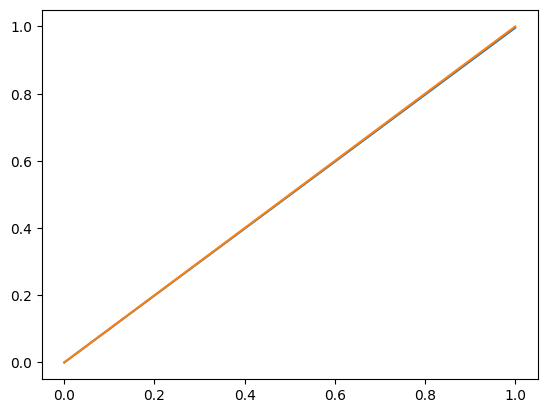

In [ ]:

n = 252
time = np.linspace(0,T,n)
dt = T/n

ll_star = helper_sigs.SigPoly(2, level+1, x_star.tolist() )
inv_coeffs = np.array( (ll_star.tensor(t)).coefficients )

inventory_star = np.zeros(len(time))
for i in range(len(time)):
  cur_time = i * dt
  exp_sigs_cur_time = helper_sigs.exp_sigs_fawc( sigma = sigma, T = cur_time, level = level + 1)
  exp_sigs_cur_time = np.array(exp_sigs_cur_time.coefficients)
  inventory_star[i] =  np.dot( inv_coeffs, exp_sigs_cur_time )


plt.plot(time,inventory_star)
plt.plot(time,time)
plt.show()

##Alternative risk criterion

We want to minimize the expression
$$\mathbb{E}\left[\int_0^T (\theta^2_t + \lambda Q^\theta_t S_t)dt \right]$$

Where again $Q^\theta_t$ is defined by
$$Q^\theta_t := q_0 - \int_0^t \theta_s ds$$ and we impose $$Q^\theta_T = 0,$$ we can impose this by summing a term
$$\mathcal{N}\left( q_0 - \int_0^T \theta_t dt\right)^2$$ and letting $\mathcal{N} \to +\infty$, in practice it's enough to set a very high $\mathcal{N}$ such as $999$, we will thus minimize the objective

$$\mathbb{E}\left[\int_0^T (\theta^2_t + \lambda Q^\theta_t S_t)dt + 999 \cdot \left(q - \int_0^T \theta_t dt \right)^2\right]$$

In [ ]:
import helper_sigs
import iisignature
import numpy as np
import sympy

level = 3
truncate = 2*level + 3
dimension = 2
lamb = 10
q0 = 1
sigma = 1
S0 = 1
T = 1

full_paths = helper_sigs.simulate_paths_geometric_brownian(m = 5000, S0 = S0, mu = 0, sigma = sigma, seed = 42, T = 1.0, n = 252)

emptyword = helper_sigs.SigPoly(2,truncate,[1,0,0])
x = helper_sigs.SigPoly(2,truncate,[0,0,1])
t = helper_sigs.SigPoly(2,truncate,[0,1,0])

ell = helper_sigs.create_variable(dimension , level, truncate)
S_t =  helper_sigs.SigPoly(2,truncate,[S0,0,1])
Q_t = q0*emptyword - ell.tensor(t)

value_func = ell*ell + lamb*(Q_t*S_t)
value_func = value_func.tensor(t)

sigs = iisignature.sig(full_paths, value_func.level)
exp_sigs = np.mean(sigs, axis = 0)
exp_sigs = np.hstack([[1],exp_sigs])

print(value_func.level)
F = value_func.inner(   exp_sigs   )
G = (Q_t*Q_t).inner(   exp_sigs   )
print(P)
print(G)
#print(second_term)

P = F + 1000*G

7
1001.00333333333*x0**2 + 1001.00249999994*x0*x1 + 275.70636870691*x0*x10 - 1.46311246981526*x0*x11 + 9.97885711636256*x0*x12 + 216.836156666015*x0*x13 + 883.99526650138*x0*x14 - 1.14166246107084*x0*x2 + 333.667333333313*x0*x3 + 5.50547012138578*x0*x4 - 3.32356297852514*x0*x5 + 719.357851874166*x0*x6 + 83.4168055555521*x0*x7 + 1.68695773026257*x0*x8 + 1.06577677662934*x0*x9 - 2005.02089864377*x0 + 250.333833333318*x1**2 + 137.928484371651*x1*x10 - 0.731887231613716*x1*x11 + 4.99228758485801*x1*x12 + 108.475648639346*x1*x13 + 442.256137989645*x1*x14 - 0.568077937392712*x1*x2 + 166.916944444438*x1*x3 + 2.75441977650227*x1*x4 - 1.6619787848194*x1*x5 + 359.8214692276*x1*x6 + 41.7333928571475*x1*x7 + 0.843993825834627*x1*x8 + 0.533284120989105*x1*x9 - 1001.67644166394*x1 + 332.017612030933*x10**2 + 34.3974492647672*x10*x11 + 261.097105861246*x10*x12 + 347.932182358859*x10*x13 + 4864.74745395612*x10*x14 + 513.152783567816*x10*x2 + 45.9920047146857*x10*x3 + 210.232146170563*x10*x4 + 151.5295

In [ ]:
import sympy as sp
import numpy as np

# P: sympy expression already defined
# Example: P = ...

# 1) pick variables (x0..x6 present in P)
vars = sorted(P.free_symbols, key=lambda s: int(s.name[1:]))  # x0,x1,...
n = len(vars)
I = np.eye(n)

# 2) regularize: P_reg = P - rho * sum x_i^2
rho = 0  # start with 0, increase if needed
Preg = P - rho * sum(v**2 for v in vars)

# 3) compute Hessian and linear term (gradient at 0)
Hsym = sp.hessian(Preg, vars)
gsym = sp.Matrix([sp.diff(Preg, v) for v in vars])

H = np.array(Hsym, dtype=float)
g0 = np.array(gsym.subs({v: 0 for v in vars}), dtype=float).reshape(-1)

# 4) check concavity (need all eigenvalues < 0 for a unique max)
eig = np.linalg.eigvalsh(H)
print("eig min/max:", eig.min(), eig.max())

# If eig.max() >= 0, bump rho and rebuild Preg/H/g0, e.g.
# rho = 10.0

# 5) solve ∇Preg(x)=0  =>  H x + g0 = 0
x_star = -np.linalg.solve(H, g0)

# 6) objective value at optimum
f = sp.lambdify(vars, Preg, "numpy")
Pmax = float(f(*x_star))

print("rho =", rho)
print("x* =", x_star)
print("max Preg(x*) =", Pmax)

eig min/max: -11089.691146172543 16188.781877256102
rho = 0
x* = [ 3.50687163e+00 -5.00006219e+00  2.55662331e+00 -3.20340123e-02
 -2.55417915e+00 -5.10817518e+00  1.17452030e-05 -1.33275544e-02
  2.04300832e-02  1.26593278e-02 -1.50809388e-02 -3.01540411e-02
  1.09676439e-03  2.40349290e-02 -5.11619260e-05]
max Preg(x*) = 3.2391757850780323


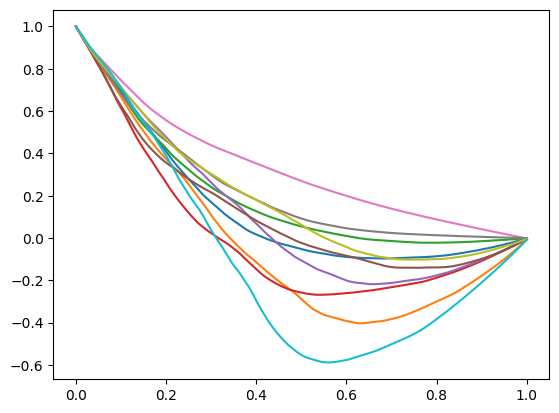

In [ ]:
import matplotlib.pyplot as plt

n = 252
time = np.linspace(0,T,n)
dt = T/n

ll_star = helper_sigs.SigPoly(2, level+2, x_star.tolist() )
inv_coeffs = np.array( (ll_star.tensor(t)).coefficients )
inv_coeffs = -1*inv_coeffs
inv_coeffs[0] = q0

m = 10
inventory_star = np.zeros((len(time),m))
for i in range(len(time)):
  cur_time = i * dt
  sigs_cur_time = iisignature.sig(full_paths[:m,:i+1,:], level+1)
  sigs_cur_time = np.hstack([np.ones((m, 1)),sigs_cur_time])
  inventory_star[i,:] =  np.dot(  sigs_cur_time, inv_coeffs )

for j in range(m):
  plt.plot(time,inventory_star[:,j])
plt.show()

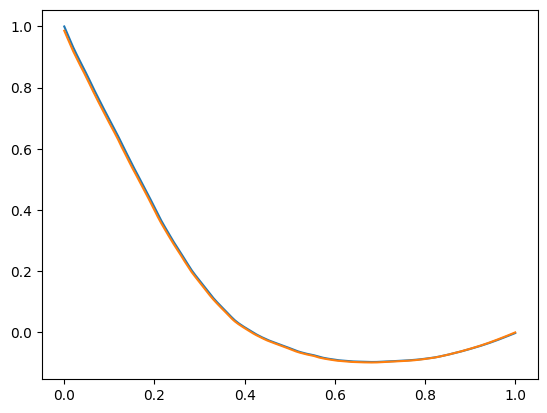

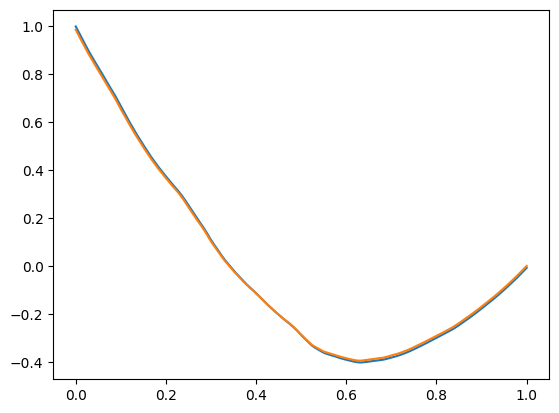

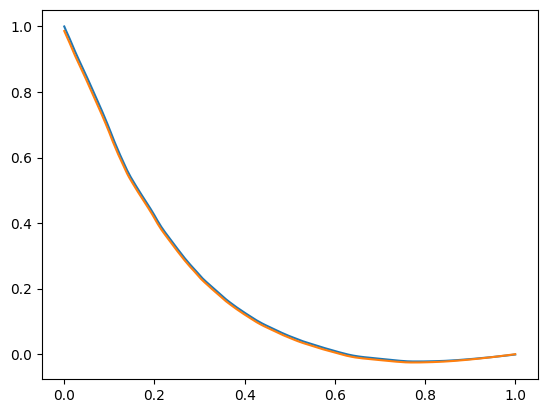

In [ ]:
S = full_paths[:, :, 1]              # shape (m, n)

integral = np.zeros_like(S)
integral[:, 1:] = dt * np.cumsum(S[:, :-1], axis=1)

inventory_starstar = (1 - full_paths[:,:,0] / T) * (q0 - (lamb * T / 4) * integral)

for j in range(3):
  plt.plot(time,inventory_star[:,j])
  plt.plot(time,x_star[j,1:])
  plt.show()

###Price impact case

Here we consider the price-impact
$$\widehat{S}_t = S_t + \kappa (Q_t - Q_0)$$
which leads to the expected value function
$$\mathbb{E}\left[\int_0^T (\theta^2_t + \kappa^2 (Q^\theta_t)^2 + \lambda Q^\theta_t S_t)dt \right]$$

Where again $Q^\theta_t$ is defined by
$$Q^\theta_t := q_0 - \int_0^t \theta_s ds$$, again we can impose $Q_T = 0$ simply by summing a term
$$\mathcal{N}\left( q_0 - \int_0^T \theta_t dt\right)^2$$ and letting $\mathcal{N} \to +\infty$, in practice it's enough to set a very high $\mathcal{N}$ such as $999$, we will thus minimize the objective

$$\mathbb{E}\left[\int_0^T (\theta^2_t + \kappa^2 Q^2_t + \lambda Q^\theta_t S_t)dt  + 999 \cdot \left(q - \int_0^T \theta_t dt \right)^2\right]$$

In [ ]:
import helper_sigs
import iisignature
import numpy as np
import sympy

level = 3
truncate = 2*level + 3
dimension = 2
lamb = 10
q0 = 1
sigma = 1
S0 = 1
T = 1
kappa = 5

full_paths = helper_sigs.simulate_paths_geometric_brownian(m = 5000, S0 = S0, mu = 0, sigma = sigma, seed = 42, T = 1.0, n = 252)

emptyword = helper_sigs.SigPoly(2,truncate,[1,0,0])
x = helper_sigs.SigPoly(2,truncate,[0,0,1])
t = helper_sigs.SigPoly(2,truncate,[0,1,0])

ell = helper_sigs.create_variable(dimension , level, truncate)
S_t =  helper_sigs.SigPoly(2,truncate,[S0,0,1])
Q_t = q0*emptyword - ell.tensor(t)

value_func = ell*ell + lamb*(Q_t*S_t) + (kappa**2)*(Q_t*Q_t)
value_func = value_func.tensor(t)

sigs = iisignature.sig(full_paths, value_func.level)
exp_sigs = np.mean(sigs, axis = 0)
exp_sigs = np.hstack([[1],exp_sigs])

print(value_func.level)
F = value_func.inner(   exp_sigs   )
G = (Q_t*Q_t).inner(   exp_sigs   )
#print(second_term)

P = F + 1000*G

9


In [ ]:
import sympy as sp
import numpy as np

# P: sympy expression already defined
# Example: P = ...

# 1) pick variables (x0..x6 present in P)
vars = sorted(P.free_symbols, key=lambda s: int(s.name[1:]))  # x0,x1,...
n = len(vars)
I = np.eye(n)

# 2) regularize: P_reg = P - rho * sum x_i^2
rho = 0  # start with 0, increase if needed
Preg = P - rho * sum(v**2 for v in vars)

# 3) compute Hessian and linear term (gradient at 0)
Hsym = sp.hessian(Preg, vars)
gsym = sp.Matrix([sp.diff(Preg, v) for v in vars])

H = np.array(Hsym, dtype=float)
g0 = np.array(gsym.subs({v: 0 for v in vars}), dtype=float).reshape(-1)

# 4) check concavity (need all eigenvalues < 0 for a unique max)
eig = np.linalg.eigvalsh(H)
print("eig min/max:", eig.min(), eig.max())

# If eig.max() >= 0, bump rho and rebuild Preg/H/g0, e.g.
# rho = 10.0

# 5) solve ∇Preg(x)=0  =>  H x + g0 = 0
x_star = -np.linalg.solve(H, g0)

# 6) objective value at optimum
f = sp.lambdify(vars, Preg, "numpy")
Pmax = float(f(*x_star))

print("rho =", rho)
print("x* =", x_star)
print("max Preg(x*) =", Pmax)

eig min/max: 1.9752472846522472e-05 49919.15197496095
rho = 0
x* = [ 5.67471358e+00 -2.28403715e+01  6.76506806e-01  6.52486491e+01
  9.66993347e-01 -1.39222146e+00  1.97085551e-02 -9.90815159e+01
 -3.28066098e+00 -3.24282705e+00 -1.97755965e-02  1.23855394e-01
 -1.97358789e-02 -3.92856929e-02  4.05979094e-07]
max Preg(x*) = 6.08873358684059


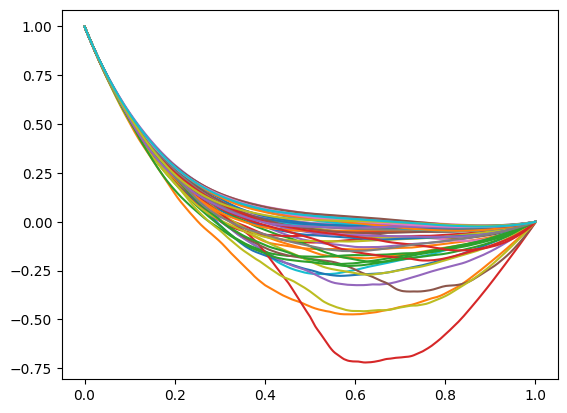

In [ ]:
import matplotlib.pyplot as plt

n = full_paths.shape[1]
time = np.linspace(0,T,n)
dt = T/n

ll_star = helper_sigs.SigPoly(2, level+2, x_star.tolist() )
inv_coeffs = np.array( (ll_star.tensor(t)).coefficients )
inv_coeffs = -1*inv_coeffs
inv_coeffs[0] = q0

m = 50
inventory_star = np.zeros((len(time),m))
for i in range(len(time)):
  cur_time = i * dt
  sigs_cur_time = iisignature.sig(full_paths[:m,:i+1,:], level+1)
  sigs_cur_time = np.hstack([np.ones((m, 1)),sigs_cur_time])
  inventory_star[i,:] =  np.dot(  sigs_cur_time, inv_coeffs )

for j in range(m):
  plt.plot(time,inventory_star[:,j])
plt.show()

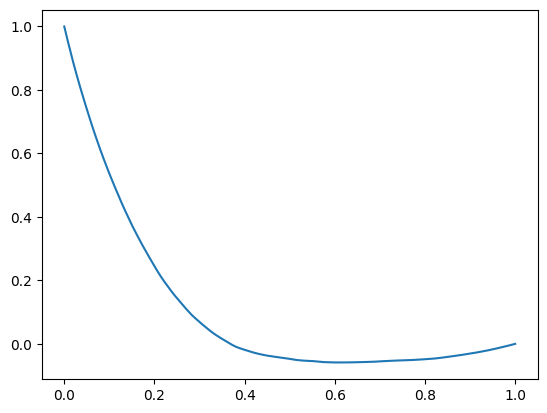

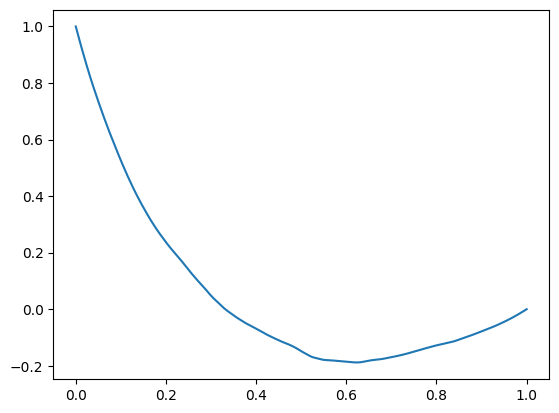

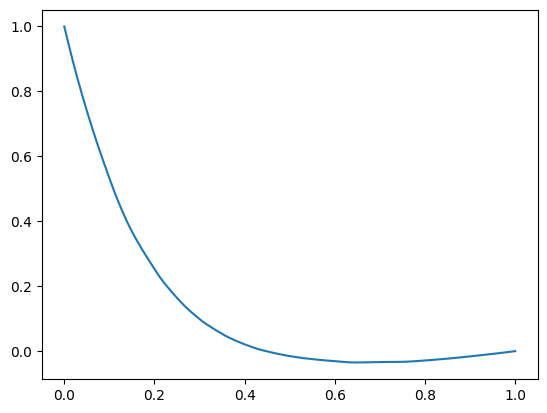

In [ ]:
t = full_paths[:, :, 0]
S = full_paths[:, :, 1]
dt = T/full_paths.shape[1]
kernel = S / (1.0 + np.cosh(kappa * (T - t)))

integral = np.zeros_like(kernel)
integral[:, 1:] = np.cumsum(
    0.5 * dt * (kernel[:, 1:] + kernel[:, :-1]),
    axis=1
)

inventory_starstar = np.sinh(kappa * (T - t)) * (
    q0 / np.sinh(kappa * T) - lamb * integral / (2.0 * kappa)
)
for j in range(3):
  plt.plot(time,inventory_starstar[j,:])
  plt.show()

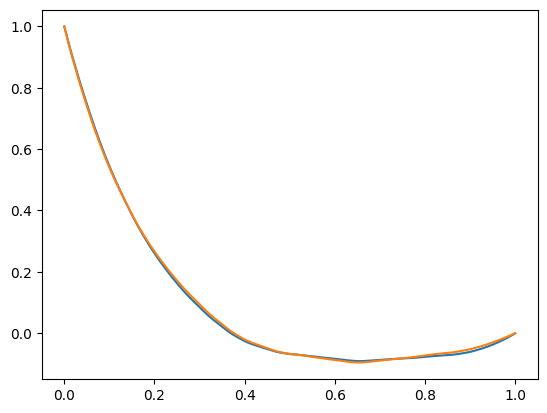

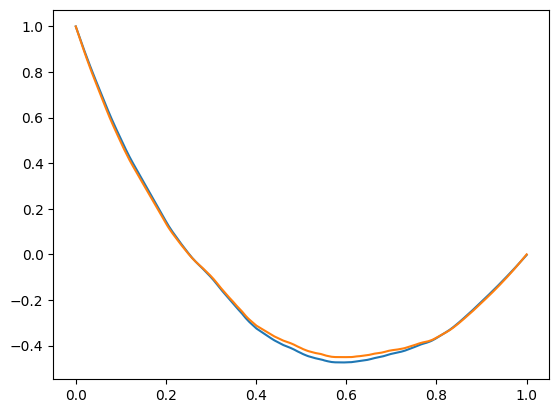

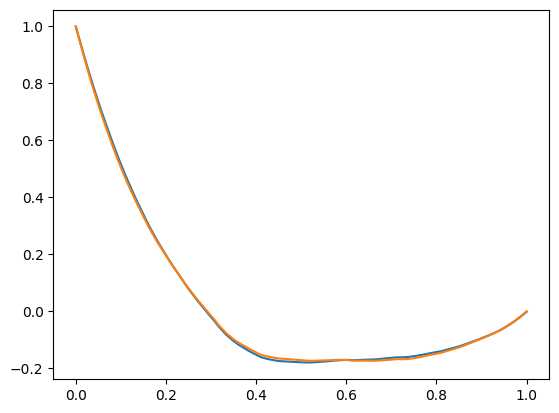

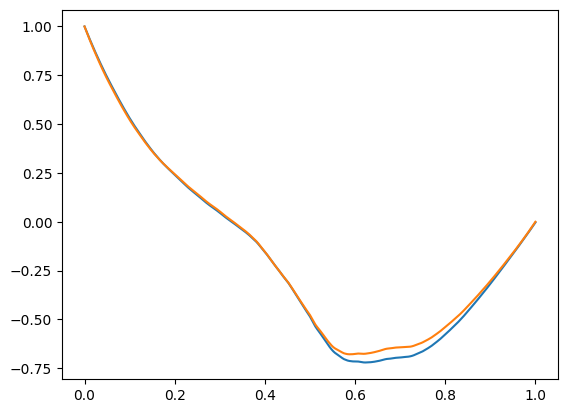

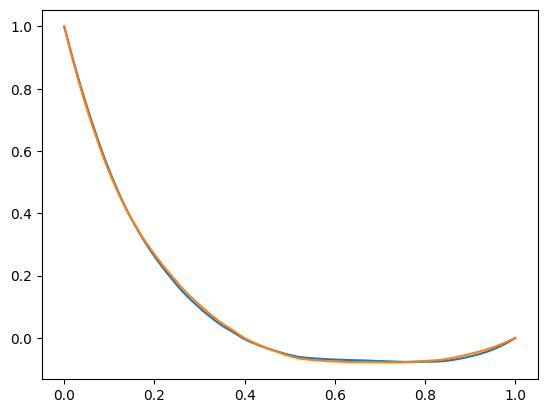

In [ ]:
for j in range(20,25):
  plt.plot(time,inventory_star[:,j])
  plt.plot(time,inventory_starstar[j,:])
  plt.show()